Cargamos constantes y rutas del fichero de metadatos

In [6]:
from pathlib import Path
import json
# Cargar metadatos 
metadata_path = Path("../src/models") / "metadata.json"
with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

IMG_SIZE = metadata["image_size"]
BATCH_SIZE = metadata["batch_size"]
CLASS_NAMES = metadata["class_names"]
NUM_CLASSES = len(CLASS_NAMES)
SEED = metadata["seed"]
MODELOS_DIR = metadata["MODELOS_DIR"]
RESULTS_DIR = metadata["RESULTS_DIR"]
EPOCHS = metadata["EPOCHS"]
ruta_dataset = metadata["DATASET_DIR"]
ruta_train = ruta_dataset + "/train"
ruta_val = ruta_dataset + "/val"
ruta_test = ruta_dataset + "/test"

print(json.dumps(metadata, indent=4, ensure_ascii=False))

{
    "class_names": [
        "1. Enfeksiyonel",
        "2. Ekzama",
        "3. Akne",
        "4. Pigment",
        "5. Benign",
        "6. Malign"
    ],
    "image_size": [
        224,
        224
    ],
    "batch_size": 16,
    "label_mode": "int",
    "seed": 42,
    "tensorflow_version": "2.10.1",
    "EPOCHS": 10,
    "SEED": 42,
    "MODELOS_DIR": "../src/models",
    "RESULTS_DIR": "../src/models/resultados",
    "DATASET_DIR": "../data/processed/"
}


Cargamos los datasets

In [7]:
import tensorflow as tf
from pathlib import Path
import shutil


BATCH_SIZE = 16  # A 32 nos quedamos si memoria
X_SIZE = 224
Y_SIZE = 224
IMG_SIZE = (X_SIZE, Y_SIZE) # A 224 nos quedamos sin recursos
SEED = 42

# Cargar TRAIN (Se queda listo para el entrenamiento)
train_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_train,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=True,
    seed=SEED
)

#Usamos class_names en validación y test para segurar que se usan los mismos índices
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

# Cargar VAL (Solo se llamará al final de cada época)
val_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_val,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names,
    shuffle=False
)

# Cargar TEST (Solo ocupará memoria al final de todo el entrenamiento)
test_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_test,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names,
    shuffle=False
)

# Optimización de flujo (SIN .cache(), solo prefetch)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("¡Datasets configurados para lectura bajo demanda desde el disco duro!")

Found 25918 files belonging to 6 classes.
Found 2356 files belonging to 6 classes.
Found 2506 files belonging to 6 classes.
¡Datasets configurados para lectura bajo demanda desde el disco duro!


In [8]:
from pathlib import Path
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

modelos_dir = Path(MODELOS_DIR)
resultados_dir = Path(RESULTS_DIR)
resultados_dir.mkdir(parents=True, exist_ok=True)

modelos_a_comparar = {
    "EfficientNetV2B0 baseline": (
        modelos_dir / "baseline_efficientnetv2b0.keras"
    ),
    "EfficientNetV2B0 DA + CW": (
        modelos_dir / "efficientnetv2b0_CW_y_DA.keras"
    ),
    "MobileNetV2": (
        modelos_dir / "mobilenetv2.keras"
    ),
    "VGG16": (
            modelos_dir / "vgg16.keras"
    )
}

# Comprobar todas las rutas antes de empezar.
for nombre, ruta in modelos_a_comparar.items():
    if not ruta.exists():
        raise FileNotFoundError(f"{nombre}: no existe {ruta}")

etiquetas = np.arange(len(CLASS_NAMES))
indice_malign = CLASS_NAMES.index("6. Malign")

y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in val_ds
]).astype(int)

filas = []
predicciones = {}
matrices = {}

for nombre, ruta in modelos_a_comparar.items():
    print("\n" + "=" * 75)
    print(nombre)
    print("Archivo:", ruta)

    modelo_evaluado = tf.keras.models.load_model(
        str(ruta),
        compile=False,
    )

    y_prob = modelo_evaluado.predict(val_ds, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)

    assert len(y_pred) == len(y_true)
    assert y_prob.shape[1] == len(class_names)

    informe = classification_report(
        y_true,
        y_pred,
        labels=etiquetas,
        target_names=class_names,
        digits=4,
        zero_division=0,
        output_dict=True,
    )

    print(classification_report(
        y_true,
        y_pred,
        labels=etiquetas,
        target_names=class_names,
        digits=4,
        zero_division=0,
    ))

    filas.append({
        "modelo": nombre,
        "archivo": str(ruta),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=etiquetas,
            average="macro",
            zero_division=0,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "recall_malign": informe[
            class_names[indice_malign]
        ]["recall"],
        "precision_malign": informe[
            class_names[indice_malign]
        ]["precision"],
    })

    predicciones[nombre] = {
        "y_true": y_true.copy(),
        "y_pred": y_pred,
        "y_prob": y_prob,
    }

    matrices[nombre] = confusion_matrix(
        y_true, y_pred, labels=etiquetas
    )

    identificador = (
    "baseline" if nombre == "EfficientNetV2B0 baseline"
    else "da_cw" if nombre == "EfficientNetV2B0 DA + CW"
    else "mobilenetv2" if nombre == "MobileNetV2"
    else "vgg16"
)
    pd.DataFrame(informe).T.to_csv(
        resultados_dir / f"informe_{identificador}_val.csv"
    )

    np.savez_compressed(
        resultados_dir / f"predicciones_{identificador}_val.npz",
        y_true=y_true,
        y_pred=y_pred,
        y_prob=y_prob,
        class_names=np.asarray(class_names),
    )

    del modelo_evaluado
    gc.collect()

comparativa = (
    pd.DataFrame(filas)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

comparativa.to_csv(
    resultados_dir / "comparativa_modelos.csv",
    index=False,
)

display(comparativa)
print(
    "\nMejor resultado por macro F1 de validación:",
    comparativa.iloc[0]["modelo"],
)


EfficientNetV2B0 baseline
Archivo: ..\src\models\baseline_efficientnetv2b0.keras
148/148 [==============================] - 7s 39ms/step
                 precision    recall  f1-score   support

1. Enfeksiyonel     0.4744    0.6981    0.5649       159
      2. Ekzama     0.3457    0.3784    0.3613        74
        3. Akne     0.8424    0.8857    0.8635       175
     4. Pigment     0.8689    0.4775    0.6163       111
      5. Benign     0.8305    0.8649    0.8473      1014
      6. Malign     0.8095    0.7278    0.7665       823

       accuracy                         0.7738      2356
      macro avg     0.6952    0.6721    0.6700      2356
   weighted avg     0.7866    0.7738    0.7751      2356


EfficientNetV2B0 DA + CW
Archivo: ..\src\models\efficientnetv2b0_CW_y_DA.keras
148/148 [==============================] - 7s 40ms/step
                 precision    recall  f1-score   support

1. Enfeksiyonel     0.3891    0.6730    0.4931       159
      2. Ekzama     0.2990    0.3919  

,modelo,archivo,accuracy,macro_f1,balanced_accuracy,recall_malign,precision_malign
0,VGG16,..\src\models\vgg16.keras,0.837012,0.728269,0.732243,0.791009,0.901662
1,MobileNetV2,..\src\models\mobilenetv2.keras,0.809423,0.704520,0.704991,0.775213,0.864499
2,EfficientNetV2B0 baseline,..\src\models\baseline_efficientnetv2b0.keras,0.773769,0.669964,0.672067,0.727825,0.809459
3,EfficientNetV2B0 DA + CW,..\src\models\efficientnetv2b0_CW_y_DA.keras,0.749576,0.641391,0.663492,0.676792,0.806078



Mejor resultado por macro F1 de validación: VGG16


Comparamos las matrices de confusión

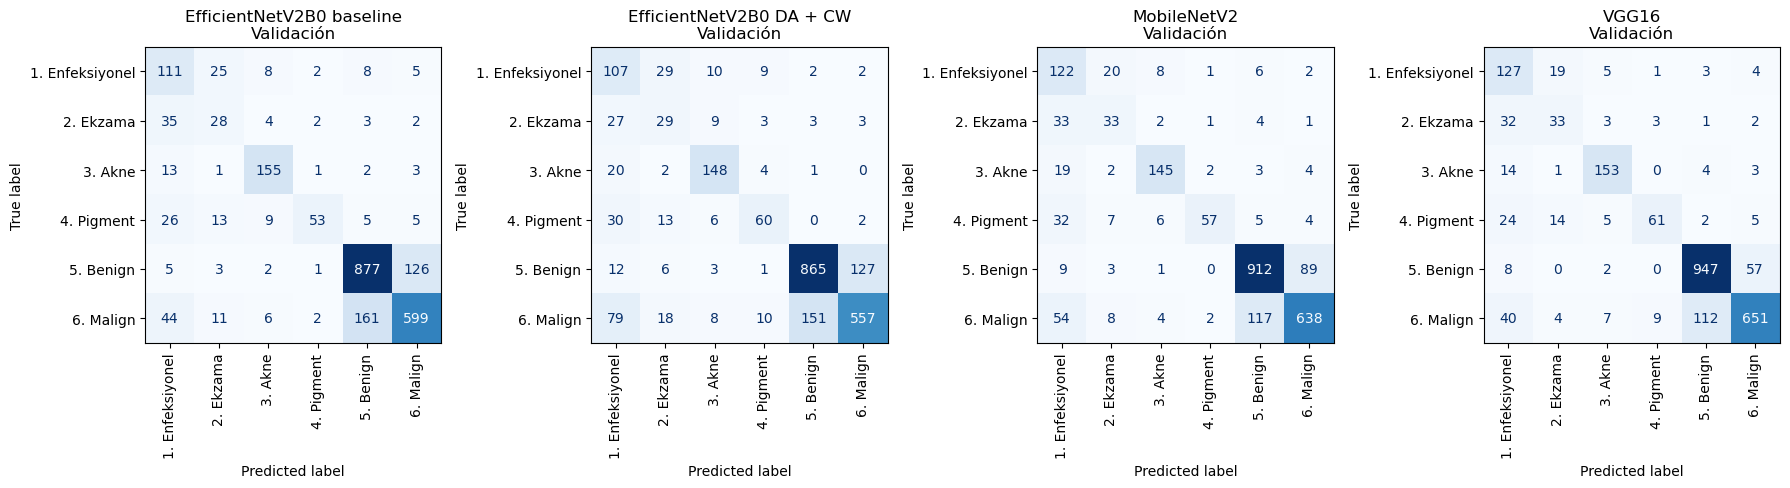

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, len(modelos_a_comparar), figsize=(18, 6.5))

for ax, (nombre, cm) in zip(axes, matrices.items()):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names,
    )

    disp.plot(
        ax=ax,
        xticks_rotation=90,
        cmap="Blues",
        colorbar=False,
        values_format="d",
    )
    ax.set_title(f"{nombre}\nValidación")

plt.tight_layout()
plt.savefig(
    resultados_dir / "comparativa_matrices.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()